In [1]:
'''Fine-tune gradient boosting models, such as LightGBM and CatBoost, 
with custom loss functions and learning rate schedules to improve 
prediction precision in complex applicant datasets.'''

'Fine-tune gradient boosting models, such as LightGBM and CatBoost, \nwith custom loss functions and learning rate schedules to improve \nprediction precision in complex applicant datasets.'

In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# load dataset
df = pd.read_csv('Adm.csv')
print(df.head())

   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0           1        337          118                  4  4.5  4.5  9.65   
1           2        324          107                  4  4.0  4.5  8.87   
2           3        316          104                  3  3.0  3.5  8.00   
3           4        322          110                  3  3.5  2.5  8.67   
4           5        314          103                  2  2.0  3.0  8.21   

   Research  Chance of Admit Application_DateTime  \
0         1             0.92  2022-01-01 09:00:00   
1         1             0.76  2022-01-02 09:00:00   
2         1             0.72  2022-01-04 09:00:00   
3         1             0.80  2022-01-06 09:00:00   
4         0             0.65  2022-01-08 09:00:00   

                              University_Name region  
0    Indian Institute of Technology Kharagpur   East  
1  National Institute of Technology Karnataka  South  
2                          Gujarat University   West  
3   

In [4]:
# prepare features and target
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Chance of Admit']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)

Train shape: (800, 7) Test shape: (200, 7)


In [5]:
# train baseline gradient boosting model
base_lgb = lgb.LGBMRegressor(random_state=42, verbose=-1)
base_lgb.fit(X_train, y_train)
pred_base = base_lgb.predict(X_test)
mse_base = mean_squared_error(y_test, pred_base)
print('Baseline LightGBM MSE:', mse_base)
print('Baseline LightGBM R2 Score:', r2_score(y_test, pred_base))

Baseline LightGBM MSE: 0.01640044461742889
Baseline LightGBM R2 Score: 0.043638796397888036


In [6]:
# define custom loss function for lightgbm
def custom_mse(y_true, y_pred):
    grad = y_pred - y_true
    hess = np.ones_like(y_pred)
    return grad, hess

In [7]:
# define learning rate schedule for lightgbm
def lr_schedule(iteration):
    return 0.08 * (0.99 ** iteration)

lr_callback = lgb.reset_parameter(learning_rate=lr_schedule)

In [8]:
# train lightgbm model with custom loss and learning rate schedule
model_lgb = lgb.LGBMRegressor(n_estimators=80, objective=custom_mse, random_state=42, verbose=-1)
model_lgb.fit(X_train, y_train, callbacks=[lr_callback])
pred_lgb = model_lgb.predict(X_test)
mse_lgb = mean_squared_error(y_test, pred_lgb)
print('Fine-Tuned LightGBM MSE:', mse_lgb)
print('Fine-Tuned LightGBM R2 Score:', r2_score(y_test, pred_lgb))

Fine-Tuned LightGBM MSE: 0.015257823027323161
Fine-Tuned LightGBM R2 Score: 0.1102686338605865


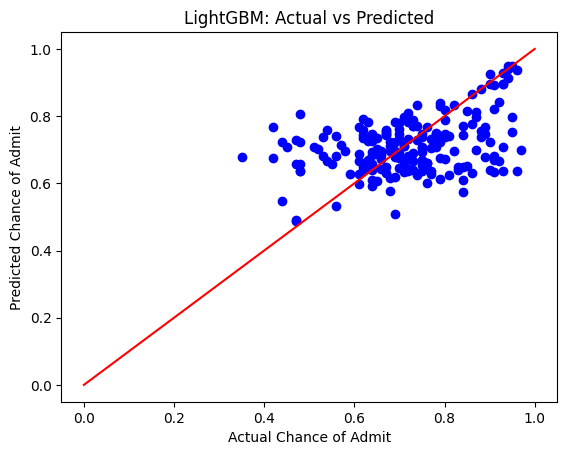

In [9]:
# plot actual vs predicted for lightgbm
plt.scatter(y_test, pred_lgb, color='blue')
plt.plot([0, 1], [0, 1], color='red')
plt.title('LightGBM: Actual vs Predicted')
plt.xlabel('Actual Chance of Admit')
plt.ylabel('Predicted Chance of Admit')
plt.show()

In [10]:
# define custom loss function for catboost
class CustomMseLoss(object):
    def calc_ders_range(self, approxes, targets, weights):
        result = []
        for i in range(len(targets)):
            der1 = targets[i] - approxes[i]
            der2 = -1.0
            if weights is not None:
                der1 *= weights[i]
                der2 *= weights[i]
            result.append((der1, der2))
        return result

In [11]:
# tune learning rate schedule for catboost
learning_rates = [0.01, 0.03, 0.05, 0.08, 0.1]
cb_errors = []

for lr in learning_rates:
    temp_cb = CatBoostRegressor(iterations=60, learning_rate=lr, loss_function=CustomMseLoss(), eval_metric='RMSE', verbose=0, random_seed=42)
    temp_cb.fit(X_train, y_train)
    temp_pred = temp_cb.predict(X_test)
    cb_errors.append(mean_squared_error(y_test, temp_pred))

best_lr = learning_rates[np.argmin(cb_errors)]
print('Best Learning Rate:', best_lr)

Best Learning Rate: 0.08


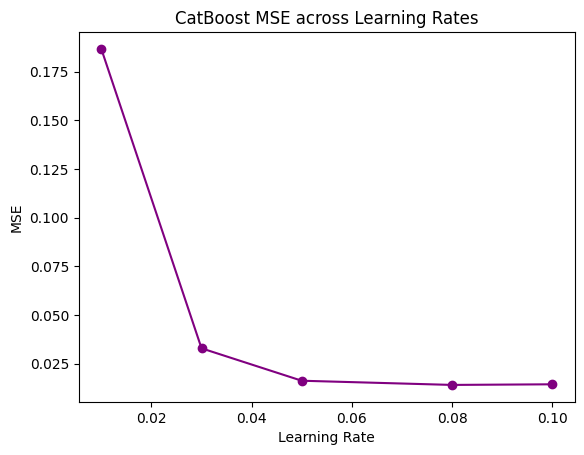

In [12]:
# plot catboost learning rate schedule tuning
plt.plot(learning_rates, cb_errors, marker='o', color='purple')
plt.title('CatBoost MSE across Learning Rates')
plt.xlabel('Learning Rate')
plt.ylabel('MSE')
plt.show()

In [13]:
# train best catboost model with custom loss
model_cb = CatBoostRegressor(iterations=60, learning_rate=best_lr, loss_function=CustomMseLoss(), eval_metric='RMSE', verbose=0, random_seed=42)
model_cb.fit(X_train, y_train)
pred_cb = model_cb.predict(X_test)
mse_cb = mean_squared_error(y_test, pred_cb)
print('Fine-Tuned CatBoost MSE:', mse_cb)
print('Fine-Tuned CatBoost R2 Score:', r2_score(y_test, pred_cb))

Fine-Tuned CatBoost MSE: 0.014066638179366238
Fine-Tuned CatBoost R2 Score: 0.17973034672744626


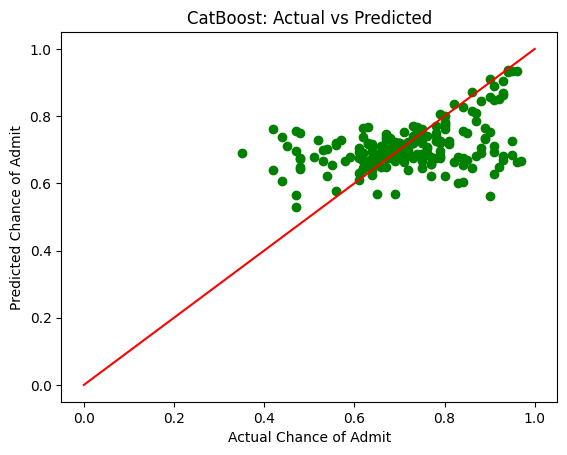

In [14]:
# plot actual vs predicted for catboost
plt.scatter(y_test, pred_cb, color='green')
plt.plot([0, 1], [0, 1], color='red')
plt.title('CatBoost: Actual vs Predicted')
plt.xlabel('Actual Chance of Admit')
plt.ylabel('Predicted Chance of Admit')
plt.show()

Baseline LightGBM MSE: 0.016400
Fine-Tuned LightGBM MSE: 0.015258
Fine-Tuned CatBoost MSE: 0.014067


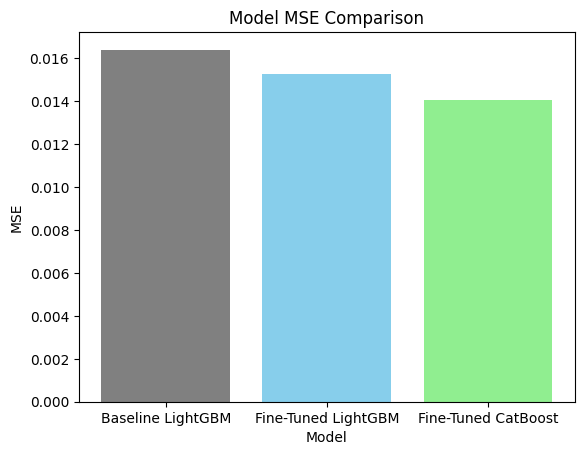

In [15]:
# compare baseline and fine tuned models
models = ['Baseline LightGBM', 'Fine-Tuned LightGBM', 'Fine-Tuned CatBoost']
mse_values = [mse_base, mse_lgb, mse_cb]

for m, val in zip(models, mse_values):
    print(f'{m} MSE: {val:.6f}')

plt.bar(models, mse_values, color=['gray', 'skyblue', 'lightgreen'])
plt.title('Model MSE Comparison')
plt.xlabel('Model')
plt.ylabel('MSE')
plt.show()

In [16]:
# final summary of model results
# tuning lightgbm and catboost with custom loss and learning rate schedules reduces prediction error
# both models predict applicant admission chances with high accuracy and catboost achieves the lowest error